In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
path = "/home/kushal/repos/td-svd-sandbox/dendrites_rect.tif"

In [3]:
movie = tifffile.imread(path)[:15_000]#, ::2, ::2]#[:, ::2, ::2]

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
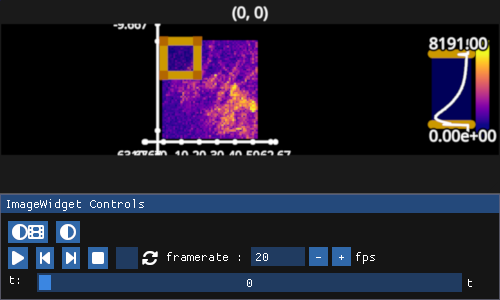

In [4]:
iw_movie = fpl.ImageWidget(movie)
rs = iw_movie.managed_graphics[0].add_rectangle_selector()
iw_movie.show()

In [5]:
movie.shape

(15000, 55, 53)

In [6]:
row_ixs, col_ixs = (
    np.array([14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30,
        31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41]),
    np.array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
        18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34,
        35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45])
)

In [7]:
row_slice = slice(row_ixs[0], row_ixs[-1] + 1)
col_slice = slice(col_ixs[0], col_ixs[-1] + 1)
movie_sub = movie[:, row_slice, col_slice]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
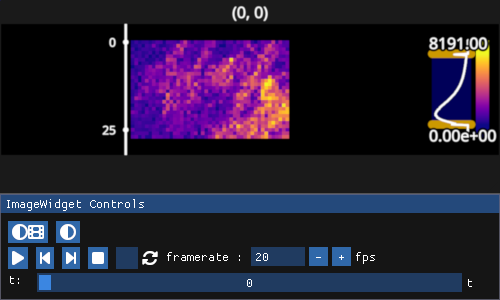

In [8]:
iw_sub = fpl.ImageWidget(movie_sub)
iw_sub.show()

In [9]:
iw_sub.window_funcs = {"t": (np.mean, 13)}

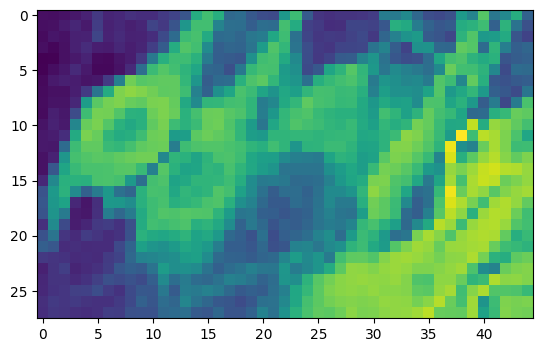

In [10]:
plt.imshow(movie_sub.std(axis=0))

In [11]:
from skophys.preprocessing import UnVectorizer, Vectorizer

/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [12]:
unvec = UnVectorizer(movie_sub.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie_sub)

In [13]:
X.shape

(1260, 15000)

In [14]:
n_pixels = X.shape[0]

In [269]:
lag = 4
lag_step = 3

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * lag_step * 2], X[i, (lag * lag_step * 2) - 1:])[::lag_step])

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i

In [270]:
Hs[0].shape

(8, 14977)

In [271]:
H.shape

(10080, 14977)

In [272]:
mu0 = np.mean(H[:lag * n_pixels])
mu1 = np.mean(H[lag * n_pixels:])

In [273]:
mu0

np.float64(2539.60523442824)

In [274]:
H[:lag * n_pixels] -= mu0
H[lag * n_pixels:] -= mu1

In [275]:
past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
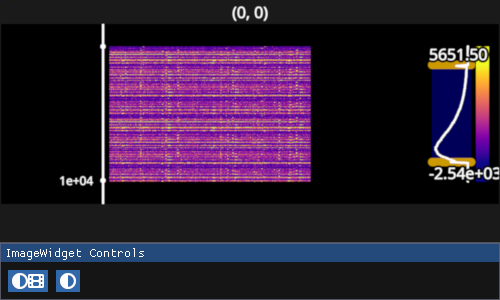

In [276]:
fpl.ImageWidget(H).show(maintain_aspect=True)

In [277]:
H.shape

(10080, 14977)

In [278]:
past.shape

(5040, 14977)

In [ ]:
PP = past @ past.T / past.shape[1]
FF = future @ future.T / future.shape[1]
PF = past @ future.T / past.shape[1]

In [ ]:
np.linalg.norm(PP - PP.T, ord="fro")

In [ ]:
evals, evecs = linalg.eigh(PP)

In [ ]:
plt.plot(evals < 0)

In [ ]:
PP_inv_sqrt = linalg.pinv(linalg.sqrtm(PP))
FF_inv_sqrt = linalg.pinv(linalg.sqrtm(FF))

K_bar = PP_inv_sqrt @ PF @ FF_inv_sqrt

In [ ]:
PP_inv_sqrt

In [ ]:
K_bar

In [ ]:
n_pixels * lag

In [ ]:
U, S, Vh = np.linalg.svd(K_bar,full_matrices=False)

# mapping data to the left and right sigular vectors
left_vec = PP_inv_sqrt @ U
right_vec = FF_inv_sqrt @ Vh.T

# projection of data onto left and right singular vectors
# proj_left = past.T @ left_vec
# proj_right = future.T @ right_vec

proj_left = left_vec.T @ past
proj_right = right_vec.T @ future

In [ ]:
plt.figure(figsize=(3, 3))
plt.plot(S / S.max(),'o-')

plt.figure(figsize=(3, 3))
plt.plot(left_vec[:, :2])
plt.title("left")

plt.figure(figsize=(3, 3))
plt.plot(right_vec[:, :2])
plt.title("right")

In [ ]:
plt.plot((S / S.max())[:50],'o-')

In [ ]:
S_MAX = 25

In [ ]:
left_vec[:, 1].shape

In [ ]:
left_vec[:, 1][n_pixels * i:(i + 1) * n_pixels].shape

In [ ]:
X.shape

In [ ]:
i = 0
q = left_vec[:, 1][n_pixels * i:(i + 1) * n_pixels] @ X
# unvec.transform()

In [ ]:
q.shape

In [ ]:
plt.plot(q)

In [ ]:
proj_left[:4].shape

In [ ]:
from ipywidgets import VBox

In [ ]:
fig_proj = fpl.Figure()

lc = fig_proj[0, 0].add_line_collection(proj_left[:10], cmap="tab10")
lc[:].colors[:, -1] = 0.5
ls = lc.graphics[0].add_linear_selector()

iw = fpl.ImageWidget(movie_sub)

def update(ev):
    if isinstance(ev, dict):
        index = ev["t"]

    else:
        index = ev.get_selected_index()
        
    ls.selection = index
    iw.current_index = {"t": int(index)}

ls.add_event_handler(update, "selection")
iw.add_event_handler(update, "current_index")


VBox([iw.show(), fig_proj.show(maintain_aspect=False)])

In [ ]:
proj_left.shape

In [ ]:
left_vec.shape

In [ ]:
np.linalg.inv(left_vec.T).shape

In [ ]:
proj_left[1].reshape(1, -1).shape

In [ ]:
left_vec.shape

In [ ]:
proj_left[1]

In [ ]:
left_vec.T[1].shape

In [ ]:
past.shape

In [ ]:
plt.plot(right_vec.T[1] @ future)

In [ ]:
plt.plot(left_vec.T[1][n_pixels:n_pixels * 2] @ past[n_pixels:n_pixels * 2])

In [ ]:
plt.plot(left_vec.T[1][n_pixels:n_pixels * 2] @ past[n_pixels:n_pixels * 2])

In [ ]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag)]

# Slider to move through each component

In [ ]:
from ipywidgets import IntSlider, HBox

In [ ]:
S_INDEX = 0

In [ ]:
fig = fpl.Figure(shape=(2, 1), size=(1700, 800), controller_ids="sync", names=["past", "future"])

left_lag_projs = fig[0, 0].add_line_collection([left_vec.T[S_INDEX][lag_slices[i]] @ past[lag_slices[i]] for i in range(lag)], cmap="tab10", thickness=1)
right_lag_projs =fig[1, 0].add_line_collection([right_vec.T[S_INDEX][lag_slices[i]] @ future[lag_slices[i]] for i in range(lag)], cmap="tab10", thickness=1)

ls1 = left_lag_projs.graphics[0].add_linear_selector()
ls2 = right_lag_projs.graphics[0].add_linear_selector()

fig.show(maintain_aspect=False)

for subplot in fig:
    subplot.toolbar = False

iw_space = fpl.ImageWidget(
    [
        *[unvec.transform(left_vec.T[S_INDEX][lag_slices[i]]) for i in range(lag)],
        *[unvec.transform(right_vec.T[S_INDEX][lag_slices[i]]) for i in range(lag)]
    ], 
    cmap="seismic_r", 
    names=[
        *[f"past lag: {i}" for i in range(lag)],
        *[f"future lag: {i}" for i in range(lag)]
    ],
    figure_shape=(2, lag),
    figure_kwargs={"size": (1700, 700)},
)

iw_sub = fpl.ImageWidget(movie_sub, cmap="gnuplot2", figure_kwargs={"size": (900, 800)})

def update_time_ix(index):
    if isinstance(index, dict):
        index = index["t"]
    else:
        index = index.get_selected_index()

    iw_sub.current_index = {"t": index}
    ls1.selection = index
    ls2.selection = index


ls1.add_event_handler(update_time_ix, "selection")
ls2.add_event_handler(update_time_ix, "selection")
iw_sub.add_event_handler(update_time_ix, "current_index")

for subplot in iw_space.figure:
    subplot.toolbar = False

def update_s_index(change):
    index = change["new"]
    global S_INDEX
    S_INDEX = index

    for g, a in zip(fig[0, 0].graphics[0], [left_vec.T[S_INDEX][lag_slices[i]] @ past[lag_slices[i]] for i in range(lag)]):
        g.data[:, 1] = a

    for g, a in zip(fig[1, 0].graphics[0], [right_vec.T[S_INDEX][lag_slices[i]] @ future[lag_slices[i]] for i in range(lag)]):
        g.data[:, 1] = a

    new_spatial = [
        *[unvec.transform(left_vec.T[S_INDEX][lag_slices[i]]) for i in range(lag)],
        *[unvec.transform(right_vec.T[S_INDEX][lag_slices[i]]) for i in range(lag)]
    ]

    iw_space.set_data(new_spatial)
    for subplot in fig:
        subplot.auto_scale()
    

s_index_slider = IntSlider(description="S_INDEX", min=0, max=S_MAX, value=S_INDEX)
s_index_slider.observe(update_s_index, "value")

HBox([VBox([s_index_slider, fig.show(maintain_aspect=False) , iw_space.show()]), iw_sub.show()])

In [268]:
u_, s_, v_ = linalg.svd(X)

In [156]:
u_.shape

(1260, 1260)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
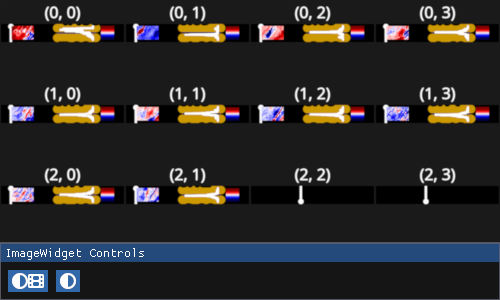

In [159]:
fpl.ImageWidget([unvec.transform(u_[:, i]) for i in range(10)], cmap="seismic").show()

In [88]:
cval = 2e-5
for g in iw_space.managed_graphics:
    g.vmin = -cval
    g.vmax = cval
    g.cmap = "seismic_r"

In [252]:
proj_left[s_ix].shape

(1993,)

In [248]:
left_vec.T[s_ix][lag_slices[-1]]

(99,)

In [257]:
fig_p = fpl.Figure()
fig_proj = fpl.Figure()

lc = fig_proj[0, 0].add_line_collection(proj_right[:4], cmap="tab10")
ls = lc.graphics[0].add_linear_selector()

iw = fpl.ImageWidget(unvec.transform(np.outer(left_vec.T[s_ix][lag_slices[-1]], proj_left[s_ix])))

def update(ev):
    if isinstance(ev, dict):
        index = ev["t"]

    else:
        index = ev.get_selected_index()
        
    ls.selection = index
    iw.current_index = {"t": int(index)}

ls.add_event_handler(update, "selection")
iw.add_event_handler(update, "current_index")


VBox([iw.show(), fig_proj.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

RFBOutputContext()

In [297]:
u, s, v = np.linalg.svd(left_vec.T[s_ix].reshape(n_pixels, lag), full_matrices=False)

In [298]:
u.shape

(108, 4)

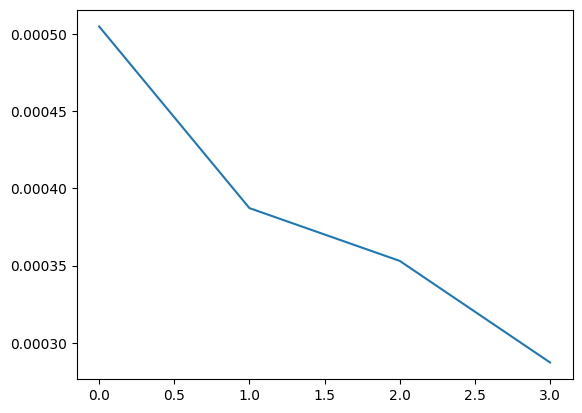

In [299]:
plt.plot(s)

RFBOutputContext()

JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
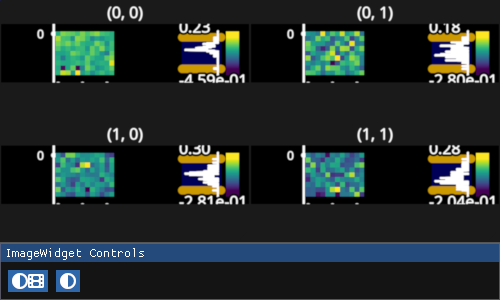

In [305]:
fpl.ImageWidget([unvec.transform(u[:, i]) for i in range(4)], cmap="viridis").show()

<Axes: >

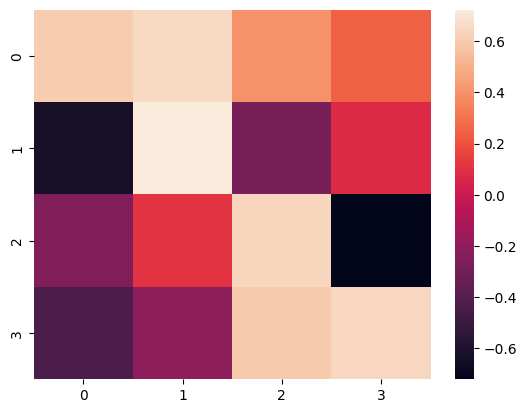

In [324]:
sns.heatmap(v)

In [ ]:
fpl.ImageWidget(unvec.transform(left_vec.T[1][lag_slices[3]]), graphic_kwargs={"vmin": -5e-5, "vmax": 5e-5}, cmap="bwr").show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
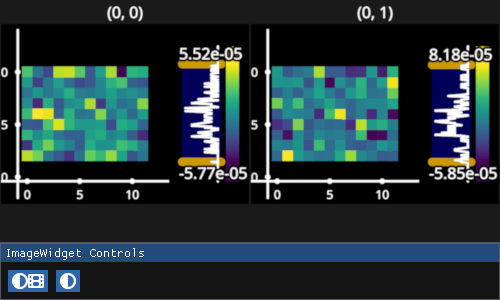

In [245]:
fpl.ImageWidget(
    [
        unvec.transform(left_vec.T[1][:n_pixels]),
        unvec.transform(left_vec.T[1][n_pixels:n_pixels * 2]),
    ],
    cmap="viridis",
).show()

In [ ]:
proj_left = left_vec.T @ past

In [785]:
A = np.array([
    [1, 0, 1],
    [0, 2, 0],
    [0, 1, 5],
])

In [787]:
evals, evecs = np.linalg.eigh(A)
evals, evecs

(array([1.        , 1.69722436, 5.30277564]),
 array([[ 1.        ,  0.        ,  0.        ],
        [ 0.        , -0.95709203,  0.28978415],
        [ 0.        ,  0.28978415,  0.95709203]]))

In [788]:
scipy.linalg.sqrtm(np.linalg.inv(A))

array([[ 1.        ,  0.05156554, -0.1381966 ],
       [ 0.        ,  0.70710678,  0.        ],
       [ 0.        , -0.08663106,  0.4472136 ]])

In [789]:
np.linalg.inv(scipy.linalg.sqrtm(A))

array([[ 1.        ,  0.05156554, -0.1381966 ],
       [ 0.        ,  0.70710678,  0.        ],
       [ 0.        , -0.08663106,  0.4472136 ]])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
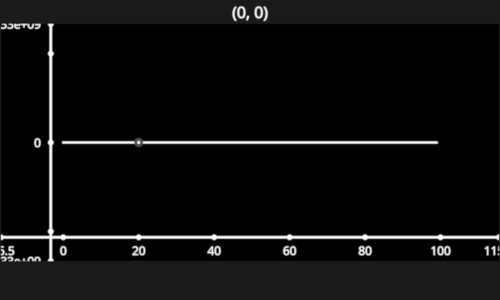

In [838]:
xs = np.linspace(0, 10, 100)
ys = np.sin(xs)

fig = fpl.Figure()

line = fig[0, 0].add_line(ys)
sel = line.add_linear_selector()
sel.selection = 20

fig[0, 0].camera.local.scale_y = 1e9

fig.show(maintain_aspect=False)

In [ ]:
fig.canvas.

In [843]:
fig.renderer.snapshot().shape

(600, 1000, 4)

In [829]:
from simplejpeg import encode_jpeg

In [844]:
a = np.random.rand(3840*2, 2160*2, 3).astype(np.uint8)
a.shape

(7680, 4320, 3)

In [845]:
%%timeit
encode_jpeg(a, quality=80)

72.7 ms ± 904 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)
